# Power of Data in Quantum Machine Learning — a reproduction notebook

*Huang, Broughton, Mohseni, Babbush, Boixo, Neven, McClean, Nature Communications 12, 2631 (2021), [arXiv:2011.01938](https://arxiv.org/abs/2011.01938).*

This notebook walks through the reproduction as a scientific argument: what the paper claims, how we test it, what the evidence shows, which alternative explanations we ruled out, and what we could not test. It also covers a **MerLin photonic adaptation** of the same methodology on linear optics.

**How to use it.** Run every cell from the top on a laptop CPU (about 4 minutes). Two kinds of evidence appear:

| Tag | Meaning |
|---|---|
| 🟢 **live** | computed in this notebook, small and fast, smoke-sized model grids |
| 📦 **stored** | loaded from the full runs (10 seeds, paper grids; up to 55,000 s of compute) in `results/`, produced by `lib/` through `implementation.py` |

Every result section is also labelled with its role: **[Reproduction]** (faithful to the paper), **[Control]** (tests an alternative explanation), **[Robustness]** (how stable the result is), **[Extension]** (not in the paper: the MerLin adaptation and an extra baseline).

**Bottom line, previewed** (argued in Section 12): the claim *directions* reproduce at n ≤ 20 (the paper goes to n = 30), several absolute values do not, and no quantum advantage appears on natural labels. The photonic adaptation reproduces the same mechanism, and it strengthens with size.

In [1]:
# Setup: paths, library imports, versions. Core logic lives in lib/; this notebook calls it.
import json
import platform
import sys
import time
import warnings
from pathlib import Path

PROJECT_DIR = Path.cwd()
assert (PROJECT_DIR / "lib" / "runner.py").is_file(), "run the notebook from papers/power_of_data_qml"
REPO_ROOT = PROJECT_DIR.parents[1]
DATA_ROOT = REPO_ROOT / "data"
RESULTS = PROJECT_DIR / "results"
sys.path[:0] = [str(REPO_ROOT), str(PROJECT_DIR)]

import matplotlib.pyplot as plt
import merlin
import numpy as np
import pandas as pd
import sklearn
import torch
from IPython.display import display
from scipy import stats

from lib import data, embeddings, geometry, kernels, photonic_merlin, study, summary

warnings.filterwarnings("ignore", category=UserWarning)
torch.set_num_threads(4)
NOTEBOOK_STARTED = time.perf_counter()
DEVICE = "cpu"  # the live parts run on CPU only

COLORS = {"E1": "#2a78d6", "E2": "#eb6834", "E3": "#1baf7a", "PA": "#7b4fd1", "PB": "#c8414b"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.color": "#e4e3df", "axes.spines.top": False, "axes.spines.right": False})

print(f"python {platform.python_version()} | numpy {np.__version__} | torch {torch.__version__} | "
      f"scikit-learn {sklearn.__version__} | merlin {merlin.__version__} | device {DEVICE}")

python 3.12.7 | numpy 2.3.5 | torch 2.4.1 | scikit-learn 1.8.0 | merlin 0.2.3 | device cpu


In [2]:
# Stored evidence: aggregates (mean, std, 95% CI per quantity) and every individual seed.
def load_aggregate(name):
    payload = json.loads((RESULTS / f"{name}.json").read_text())
    assert payload["coverage"] == "COMPLETE", name
    frame = pd.DataFrame(payload["summary"])
    return payload, frame

GATE_PAYLOAD, GATE = load_aggregate("study_extended")                 # gate model, n = 3-16, 18, 20
PHOT_PAYLOAD, PHOT = load_aggregate("study_photonic_extended")        # MerLin, k = m/2, n = 4-18
CAPPED_PAYLOAD, CAPPED = load_aggregate("study_photonic_capped")      # MerLin, k <= 8, n = 17-20
PER_SEED = pd.read_csv(RESULTS / "per_seed_key_rows.csv")
COMPARISON = pd.DataFrame(json.loads((RESULTS / "comparison_extended.json").read_text())["rows"])

source = pd.DataFrame(
    [(name, p["observed_records"], p["expected_records"], p["coverage"], ", ".join(Path(r).name for r in p["runs"]))
     for name, p in [("gate", GATE_PAYLOAD), ("photonic k=m/2", PHOT_PAYLOAD), ("photonic capped k<=8", CAPPED_PAYLOAD)]],
    columns=["aggregate", "records", "expected", "coverage", "source runs"],
)
display(source)
print("per-seed rows:", len(PER_SEED), "| runs:", PER_SEED.run.nunique(), "| seeds:", sorted(int(v) for v in PER_SEED.seed.unique()))

,aggregate,records,expected,coverage,source runs
0,gate,640,640,COMPLETE,"run_20261016-182734, run_20261016-222551, run_..."
1,photonic k=m/2,440,440,COMPLETE,"run_20261017-141820, run_20261017-154534, run_..."
2,photonic capped k<=8,120,120,COMPLETE,"run_20261019-231148, run_20261020-031250"


per-seed rows: 36330 | runs: 11 | seeds: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


**Provenance of the stored runs** (details in `LOG.md`): code commit `e7beb6a` plus the uncommitted paper folder; configs `configs/study_reduced_local.json`, `study_reduced_remote.json`, `study_photonic_*.json`; data = official Fashion-MNIST; seeds 0–9.

| Runs | Machine | Precision | Wall-clock |
|---|---|---|---|
| gate n = 3–16 (`run_20261016-182734`, `run_20261016-222551`) | Apple M5, 10 cores | float64 | 28,411 s |
| gate n = 18, 20 (`run_20261019-070332`, `run_20261019-104320`) | NVIDIA L4 | float32 | 26,536 s |
| photonic n = 4–14 (`run_20261017-141820`, `run_20261017-154534`) | Apple M5 | float64 | 10,451 s |
| photonic n = 15–18 (3 runs) and capped n = 17–20 (2 runs) | NVIDIA L4 | float32 | 23,030 s + 29,028 s |

Environments: local Python 3.12.7 with scikit-learn 1.8; remote Python 3.12.3, torch 2.14.1+cu130, scikit-learn 1.9.1, MerLin 0.2.3 on both.

### Reductions and deviations at a glance

Every departure from the paper, where it is discussed, and its likely impact on the claims:

| Reduction or deviation | Paper | This reproduction | Likely impact | Where |
|---|---|---|---|---|
| System size | n ≤ 30 (QK ≤ 28) | gate n ≤ 20; photonic n ≤ 18 (k = m/2), n = 20 only with photons capped at 8 | the paper's large-n statements (C7 at n ≈ 28, the >20% gap) are untested | §7, §11, §12 |
| Effective input scale | 1 (implied by the text) | 0.3, fitted to the paper's geometry | geometry agreement partly by construction; E1/E2 $d$ grows more slowly | §2, §9E |
| Other circuit conventions | ambiguous (E2 phase, E3 register/time, QNN boundary) | resolved by predeclared fits to the Source Data | absolute values may shift; claim directions unchanged at n = 12 (LOG sensitivity check) | §9E, `LOG.md` |
| Engineered-label threshold | sign | median (sign gives single-class labels) | none on directions; required for a valid task | §3 |
| Selection protocol | best test score | both; verdicts use 5-fold CV | verdicts are conservative; values differ by ≤ 0.015 | §2, §9D |
| Simulator | TensorFlow-Quantum | PyTorch statevector (gate), MerLin 0.2.3 (photonic) | none expected; unit-tested against dense references | §4 |
| Hardware and precision | data-centre CPUs | M5 CPU float64 (n ≤ 16 gate, n ≤ 14 photonic); L4 GPU float32 above | bridged: geometry ≤ 1.3e-4 relative, tree metrics ≤ 0.007 | §10 |
| Labels and features | not released | regenerated with the paper's procedure | same distribution, not the same samples | §2 |
| Extra baseline | — | polynomial-kernel family added | no verdict changed | §8 |
| Photonic adaptation | not in the paper | PA/PB embeddings, no-click projected kernel, noise-free | extension only; no paper values to compare | §11 |
| Live notebook parts | — | 3 seeds, n ≤ 8, smoke grids | illustrative only; stored runs decide | §6 |

## 1. Problem statement and the paper's claim

Quantum machine learning is often motivated by "the quantum model computes something classically hard". The paper's point is that this is not enough: **once a classical learner is given data, it can learn functions that are hard to compute**, so a quantum advantage in prediction needs a separate, data-dependent argument.

The paper turns that into a test. For kernel methods, the error is bounded by the *model complexity* $s_K$ of the true labels in the kernel's feature space, and a label-free *geometric difference* $g(K^C\|K^Q)$ bounds how much worse a classical kernel can be: $s_C \le g^2 s_Q$. Small $g$ means classical ML is provably competitive.

**Claims we test** (inventory and status in `LOG.md`):

| ID | Claim | Paper figure (arXiv / journal) |
|---|---|---|
| C1 | With data, tuned classical models match or beat quantum kernels on quantum-generated labels | Fig. 1b / 3b |
| C3, C4 | The fidelity kernel's effective dimension $d$ grows to N and its $g$ collapses; the projected kernel (PQK) keeps a low $d$ and larger $g$ | Fig. 1a / 3a |
| C5, C6 | On labels engineered to saturate $s_C = g^2 s_Q$, the PQK beats the best of six tuned classical models, with a gap that follows $g$ | Fig. 2 / 4 |
| C7 | On labels engineered for the fidelity kernel, it shows no advantage at large n | Fig. S1 |
| C10 | Classical ML is best on natural labels (dress vs shirt) | Fig. 1b / 3b |

**Falsifiable research question.** *Does a tuned classical suite match or beat quantum kernels on quantum-generated labels, and does the projected quantum kernel beat it only where the data-dependent $g$ is large?*

**Evidence that would weaken the claim:**
- the fidelity kernel beating the classical suite on quantum-generated labels at large n;
- a PQK advantage that does not track $g$ (for example, a large advantage for the separable embedding E1, whose $g$ is small);
- a quantum advantage on natural labels, which would mean the engineered-label result is not the explanation.

## 2. Data, splits, metrics and evaluation protocol

**Data.** Fashion-MNIST (official release, all 70,000 images). Images are scaled to [0, 1], projected on the top-n PCA components fitted on all 70k images, and each component is standardized. Each seed draws an 800-point subsample (balanced classes). No preprocessed features or labels were released, so every label below is regenerated with the paper's procedure.

**Inputs to the quantum circuits** are the standardized features times an *effective input scale* of 0.3. The paper's text implies 1; 0.3 was fitted to the paper's published geometry values (Section 9 shows why). This is the largest deviation.

In [3]:
# 🟢 live: load Fashion-MNIST, fit PCA, draw the seed-0 subsample (lib/data.py).
pca = data.build_pca_features(DATA_ROOT, 8)
indices = data.subsample_indices(pca.labels, 800, study.stream_rng(0, study.STREAM_SUBSAMPLE_ALL))
features = pca.features(8, indices)
print(f"PCA on {pca.components.shape[0]:,} images; top-8 explained variance {pca.explained_variance_ratio[:8].sum():.3f}")
print(f"subsample: {features.shape[0]} points x {features.shape[1]} features; "
      f"per-feature mean {features.mean(0).round(2).tolist()}")
print("points per class:", np.bincount(pca.labels[indices]).tolist())
TRAIN, TEST = 600, 200
print(f"split: first {TRAIN} points train, last {TEST} test (fixed per seed, shared by every model)")

PCA on 70,000 images; top-8 explained variance 0.693
subsample: 800 points x 8 features; per-feature mean [-0.04, -0.0, 0.02, -0.03, -0.01, 0.04, 0.03, 0.07]
points per class: [74, 75, 80, 99, 82, 74, 69, 93, 71, 83]
split: first 600 points train, last 200 test (fixed per seed, shared by every model)


| Item | Setting |
|---|---|
| Datasets | (Q, E1–E3): QNN labels $\langle Z_1\rangle$ after each embedding (regression). Engineered (PQK or QK): ±1 labels built to saturate $s_C = g^2 s_Q$, 10% random flips (classification). (C): dress vs shirt (classification). |
| Split | 600 train / 200 test per seed (engineered datasets also at N = 100). Same split for every model. |
| Metrics | test MAE (Q datasets, lower is better); test accuracy (engineered, higher is better); test error (C) |
| Models | **Quantum:** fidelity kernel (QK), projected kernel (PQK), each in an SVM/SVR. **Classical (the paper's baseline):** best of six tuned families: Gaussian- and linear-kernel SVM, random forest, gradient boosting, AdaBoost, neural network. **Extension:** a polynomial-kernel model. |
| Selection protocol `paper` | best *test* score over each grid, as in the paper. It **uses the test set for selection**, so it is optimistic and only used to compare values with the paper. |
| Selection protocol `cv` | 5-fold cross-validation on the training points only; the test set is touched once. **All verdicts use `cv`.** |
| Seeds | 10 (0–9) for every stored result; each seed changes the subsample, labels and model randomness |
| Decision rule | "better" only if the paired 95% t-interval of the difference over the 10 seeds excludes 0 (frozen before the comparison) |

## 3. The minimum mathematics

**Embeddings.** Each input $x \in \mathbb{R}^n$ prepares a state $|\psi(x)\rangle$:
E1 separable rotations; E2 an IQP circuit (Hadamards, $Z$ and $ZZ$ phases); E3 a Trotterized Heisenberg chain on n+1 qubits.

**Kernels.**
- Fidelity (quantum) kernel: $K^Q_{ij} = |\langle\psi(x_i)|\psi(x_j)\rangle|^2$.
- Projected kernel: $K^{PQ}_{ij} = \exp\!\big(-\gamma\sum_k \|\rho_k(x_i)-\rho_k(x_j)\|_F^2\big)$, with $\rho_k$ the one-qubit reduced state (its three Pauli expectations).

**Effective dimension.** With $t_1 \ge t_2 \ge \dots$ the eigenvalues of $K$ normalized to $\mathrm{Tr}\,K = N$,
$d = \sum_k \frac{1}{N-k+1}\sum_{l\ge k} t_l \in [1, N]$. A kernel close to the identity has $d \approx N$: every point is orthogonal to every other, so nothing generalizes.

**Model complexity and bound.** For labels $y$, $s_K = y^\top K^{-1} y$ (regularized: $s_{K,\lambda} = y^\top (K+\lambda)^{-1}K(K+\lambda)^{-1} y$), and the prediction error of the trained model is $O(\sqrt{s_K/N})$.

**Geometric difference.** $g(K^C\|K^Q) = \sqrt{\big\|\sqrt{K^Q}\,(K^C)^{-1}\sqrt{K^Q}\big\|_\infty}$ (regularized as in the paper), so that $s_C \le g^2 s_Q$ for every $y$. The reported $g$ minimizes over classical kernels (linear, Gaussian at 9 bandwidths) and $\lambda$, keeping the training-error term $g_{tra} < 0.045$.

**Engineered labels.** Take the top eigenvector $v$ of $\sqrt{K^Q}(K^C)^{-1}\sqrt{K^Q}$ (regularized), set $y' = \sqrt{K^Q}v$, which saturates $s_C = g^2 s_Q$, threshold at the median, and flip 10% at random. These labels are **the best case for the quantum kernel by construction**; the paper uses them to show that an advantage *can* exist when $g$ is large.

## 4. Known-answer sanity checks 🟢

Before trusting any figure, each building block must reproduce a known answer. The same checks (and more) are in `tests/` (66 tests, all passing).

In [4]:
rng = np.random.default_rng(0)
checks = []

# (a) Effective dimension: rank-one kernel -> 1, identity -> N.
v = rng.standard_normal(50)
checks.append(("d(rank-one kernel) = 1", geometry.effective_dimension(np.outer(v, v)), 1.0))
checks.append(("d(identity, N=50) = 50", geometry.effective_dimension(np.eye(50)), 50.0))

# (b) Model complexity equals the squared weight norm of kernel ridge regression.
phi = rng.standard_normal((30, 8)); phi *= np.sqrt(30 / np.trace(phi @ phi.T))
kernel, labels, lam = phi @ phi.T, rng.standard_normal(30), 0.1
weights = phi.T @ np.linalg.solve(kernel + lam * np.eye(30), labels)
checks.append(("s_K = ||w||^2 (kernel ridge)", geometry.model_complexity(kernel, labels, lam), weights @ weights))

# (c) Engineered labels saturate s_C = g^2 s_Q (App. F).
def random_psd(seed, size=40):
    a = np.random.default_rng(seed).standard_normal((size, size))
    return a @ a.T + 1e-3 * np.eye(size)
k_q, k_c = random_psd(1), random_psd(2)
built = geometry.engineered_labels(k_q, k_c, 1e-12, np.random.default_rng(3), random_label_probability=0.0, threshold="median")
s_q = geometry.model_complexity(k_q, built.real_targets, 0.0)
s_c = geometry.model_complexity(k_c, built.real_targets, 1e-12)
checks.append(("engineered targets: s_C / (g^2 s_Q) = 1", s_c / (built.g_gen**2 * s_q), 1.0))

# (d) Gate simulator: the closed-form E1 kernel equals the simulated statevector kernel.
conventions = embeddings.EmbeddingConventions.from_config(json.loads((PROJECT_DIR / "configs/defaults.json").read_text())["conventions"])
small = features[:20, :5]
simulated = embeddings.compute_quantum_bank("E1", small, conventions, haar_product_state=None, qnn_couplings=None,
                                            need_quantum_kernel=True, device="cpu", complex_dtype=torch.complex128,
                                            batch_memory_mb=64, e1_analytic=False)
closed_form = embeddings.e1_quantum_kernel(conventions.input_scale * small)
checks.append(("E1 kernel: max |simulated - closed form|", np.abs(simulated.quantum_kernel - closed_form).max(), 0.0))

# (e) Photonic: a MerLin amplitude equals the permanent formula for bosons.
from itertools import permutations
def permanent(matrix):
    return sum(np.prod([matrix[i, p[i]] for i in range(len(matrix))]) for p in permutations(range(len(matrix))))
x = rng.standard_normal((1, 4))
circuit, _ = photonic_merlin.embedding_circuit("PA", 4, np.random.default_rng(2))
layer = photonic_merlin._layer(circuit, 4, merlin.MeasurementStrategy.AMPLITUDES)
amplitudes = layer(photonic_merlin.circuit_inputs("PA", torch.as_tensor(x), 0.3)).detach().numpy()[0]
haar = np.random.default_rng(2); v_mat, w_mat = photonic_merlin.haar_unitary(4, haar), photonic_merlin.haar_unitary(4, haar)
unitary = w_mat @ np.diag(np.exp(1j * 2 * 0.3 * x[0])) @ v_mat
out = (0, 1, 0, 1)   # photons enter modes 0 and 2, leave in modes 1 and 3
expected = permanent(unitary[np.ix_([1, 3], [0, 2])])
got = amplitudes[[tuple(k) for k in layer.output_keys].index(out)]
checks.append(("photonic |amplitude| vs permanent", abs(got), abs(expected)))

table = pd.DataFrame(checks, columns=["check", "computed", "expected"])
table["|difference|"] = (table.computed - table.expected).abs()
display(table.assign(computed=table.computed.map("{:.10g}".format), expected=table.expected.map("{:.10g}".format),
                     **{"|difference|": table["|difference|"].map("{:.1e}".format)}))
assert (table["|difference|"] < 1e-8).all(), "a known-answer check failed"

,check,computed,expected,|difference|
0,d(rank-one kernel) = 1,1,1,1.4e-14
1,"d(identity, N=50) = 50",50,50,0.0e+00
2,s_K = ||w||^2 (kernel ridge),1.009656108,1.009656108,4.3e-13
3,engineered targets: s_C / (g^2 s_Q) = 1,1,1,2.2e-15
4,E1 kernel: max |simulated - closed form|,7.771561172e-16,0,7.8e-16
5,photonic |amplitude| vs permanent,0.3042408296,0.3042408296,1.1e-16


**Observation:** all five known answers hold to ≤ 1e-8 (most to rounding error).
**Inference:** the effective dimension, model complexity, engineered-label construction, gate simulator and MerLin photonic amplitudes implement their definitions.
**Remaining uncertainty:** these checks validate *components*; they say nothing about whether the end-to-end pipeline reproduces the paper (Sections 6–7 address that).

## 5. Pipeline walkthrough: one (seed, n, embedding) unit 🟢

Every result in the study is built from units like this one (`lib/study.py::run_embedding_unit`). We follow seed 0, n = 8 features, embedding E3, step by step.

In [5]:
config = json.loads((PROJECT_DIR / "configs/defaults.json").read_text())
settings = study.StudySettings.from_config(config)
n, seed, embedding = 8, 0, "E3"

# Step 1: classical kernels for the g minimization (linear + 9 Gaussian bandwidths).
classical = study.build_classical_inputs(features, n, settings)
# Step 2: simulate the 800 embedded states once; keep 1-qubit Pauli expectations, the fidelity Gram and QNN labels.
bank = study.build_quantum_bank(embedding, features, n, seed, settings, conventions, torch.complex128, want_kernel=True, want_labels=True)
pqk = study.pqk_geometry_kernel(bank.pauli_features, n, settings.pqk_gamma_scale_geometry)
print(f"E3 uses {bank.n_qubits} qubits; Pauli features {bank.pauli_features.shape}; fidelity kernel {bank.quantum_kernel.shape}")

# Step 3: effective dimension and geometric difference for both quantum kernels.
for name, matrix in [("fidelity QK", bank.quantum_kernel), ("projected PQK", pqk)]:
    result = geometry.minimum_geometric_difference(matrix, classical.paper_spectra, lambdas=settings.lambdas, g_tra_threshold=settings.g_tra_threshold)
    print(f"{name:14s} d = {geometry.effective_dimension(matrix):6.1f} of 800 | g = {result.g:5.2f} "
          f"(vs {result.kernel}, lambda = {result.lam:g}, g_tra = {result.g_tra:.3f})")

# Step 4: engineered labels against the closest classical kernel.
best = geometry.minimum_geometric_difference(pqk, classical.paper_spectra, lambdas=settings.lambdas)
engineered = geometry.engineered_labels(pqk, classical.geometry_kernels[best.kernel], best.lam, np.random.default_rng(0),
                                        random_label_probability=0.1, threshold="median")
print(f"engineered labels: classes {np.unique(engineered.labels, return_counts=True)[1].tolist()}, "
      f"flipped {engineered.flipped_fraction:.1%}, g_gen {engineered.g_gen:.2f}")
print(f"QNN labels (regression targets): mean {bank.qnn_labels.mean():+.3f}, std {bank.qnn_labels.std():.3f}")

E3 uses 9 qubits; Pauli features (800, 9, 3); fidelity kernel (800, 800)
fidelity QK    d =  189.7 of 800 | g =  3.63 (vs rbf_16, lambda = 0.001, g_tra = 0.008)
projected PQK  d =    6.7 of 800 | g = 10.77 (vs rbf_4, lambda = 0.0001, g_tra = 0.037)
engineered labels: classes [398, 402], flipped 4.8%, g_gen 10.77
QNN labels (regression targets): mean -0.390, std 0.292


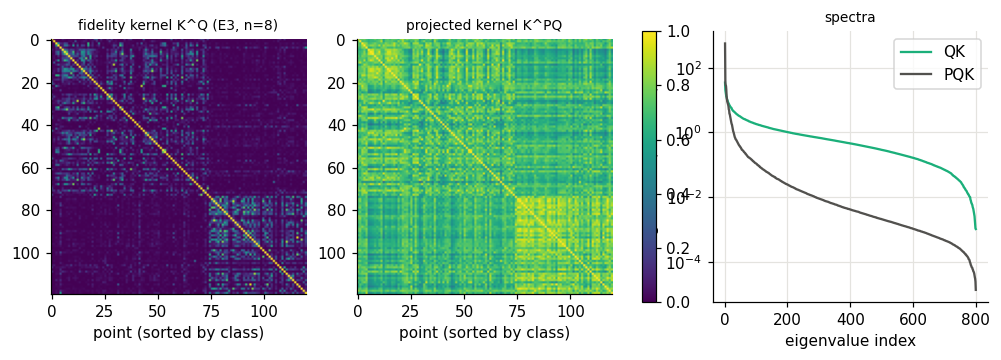

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
order = np.argsort(pca.labels[indices])[:120]
for ax, (title, matrix) in zip(axes[:2], [("fidelity kernel K^Q (E3, n=8)", bank.quantum_kernel), ("projected kernel K^PQ", pqk)]):
    im = ax.imshow(matrix[np.ix_(order, order)], vmin=0, vmax=1, cmap="viridis")
    ax.set_title(title, fontsize=9); ax.set_xlabel("point (sorted by class)"); ax.grid(False)
fig.colorbar(im, ax=axes[:2], fraction=0.025)
for name, matrix, color in [("QK", bank.quantum_kernel, COLORS["E3"]), ("PQK", pqk, "#52514e")]:
    spectrum = np.sort(np.linalg.eigvalsh(kernels.normalize_trace(matrix)))[::-1]
    axes[2].semilogy(np.arange(1, 801), np.clip(spectrum, 1e-12, None), color=color, label=name)
axes[2].set_xlabel("eigenvalue index"); axes[2].set_ylabel("eigenvalue (Tr K = N)"); axes[2].legend(); axes[2].set_title("spectra", fontsize=9)
plt.show()

**Observation:** the fidelity kernel is already nearly diagonal at n = 8 (off-diagonal entries small, flat spectrum, large $d$); the projected kernel keeps structure (a few large eigenvalues, small $d$) and has the larger $g$.
**Inference:** this is the mechanism of the paper in one unit: the fidelity kernel "sees" every point as unique, while the projected kernel keeps a classically hard but learnable geometry.

## 6. A small live experiment 🟢 [Reproduction, reduced]

To see the claims emerge rather than only reading stored numbers, we run the real study code on a reduced setting. Every scientifically important setting is explicit below. **Reductions** against the stored study: 3 seeds instead of 10, n ≤ 8 instead of ≤ 20, the `smoke` hyperparameter grids instead of the paper grids, only N = 600, and 3 of the 6 components. Selection uses **5-fold CV only**, so the test points are never used to choose a model.

We compare a small-$g$ embedding (E1), the large-$g$ gate embedding (E3) and the photonic hopping chain (PB, MerLin).

In [7]:
live_config = json.loads((PROJECT_DIR / "configs/defaults.json").read_text())
live_config["study"].update(
    components=["dimension_geometry", "quantum_dataset", "engineered_pqk"],
    engineered_train_sizes=[600],
    cv_system_sizes=[4, 6, 8],
)
live_config["models"].update(grid="smoke", protocols=["cv"], n_jobs=8)
LIVE_SEEDS, LIVE_SIZES, LIVE_EMBEDDINGS = (0, 1, 2), (4, 6, 8), ("E1", "E3", "PB")
live_settings = study.StudySettings.from_config(live_config)
print({k: live_config["study"][k] for k in ("components", "engineered_train_sizes", "cv_system_sizes")},
      {k: live_config["models"][k] for k in ("grid", "protocols", "cv_folds")}, "| input_scale", live_config["conventions"]["input_scale"])

started = time.perf_counter()
live_rows = []
for live_seed in LIVE_SEEDS:
    live_indices = data.subsample_indices(pca.labels, 800, study.stream_rng(live_seed, study.STREAM_SUBSAMPLE_ALL))
    for live_n in LIVE_SIZES:
        live_features = pca.features(live_n, live_indices)
        live_classical = study.build_classical_inputs(live_features, live_n, live_settings)
        for live_embedding in LIVE_EMBEDDINGS:
            record = study.run_embedding_unit(live_embedding, live_features, live_classical, live_n, live_seed,
                                              live_settings, conventions, torch.complex128)
            live_rows += summary.record_rows(record)
LIVE = pd.DataFrame(live_rows)
print(f"{len(LIVE_SEEDS) * len(LIVE_SIZES) * len(LIVE_EMBEDDINGS)} units in {time.perf_counter() - started:.0f} s")

{'components': ['dimension_geometry', 'quantum_dataset', 'engineered_pqk'], 'engineered_train_sizes': [600], 'cv_system_sizes': [4, 6, 8]} {'grid': 'smoke', 'protocols': ['cv'], 'cv_folds': 5} | input_scale 0.3
27 units in 228 s


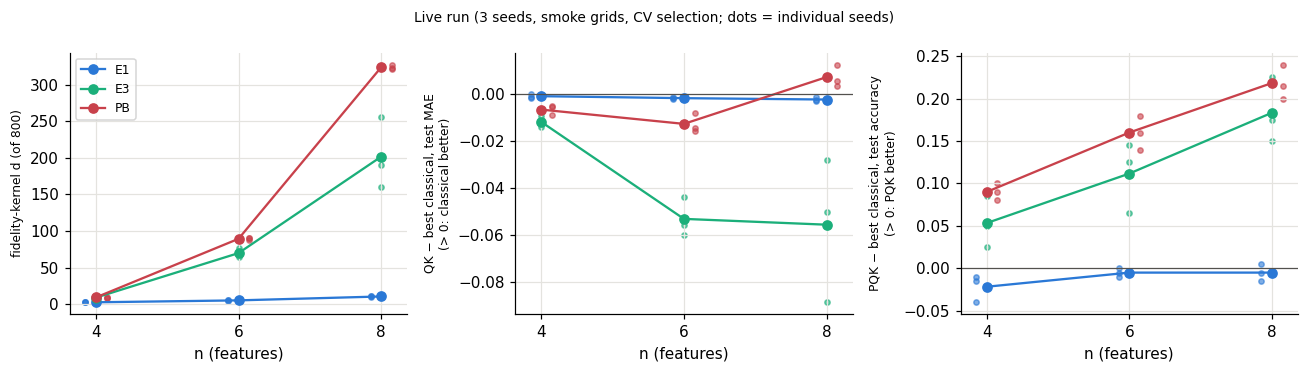

mean                  std             
embedding     E1     E3     PB     E1     E3    PB
n                                                 
4         -0.022  0.053  0.090  0.016  0.030  0.01
6         -0.005  0.112  0.160  0.005  0.042  0.02
8         -0.005  0.183  0.218  0.010  0.038  0.02

In [8]:
def live_series(component, quantity):
    rows = LIVE[(LIVE.component == component) & (LIVE.quantity == quantity)]
    return rows.pivot_table(index="n", columns="embedding", values="value", aggfunc=["mean", "std"])

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
panels = [
    ("dimension_geometry", "d_quantum_kernel", "fidelity-kernel d (of 800)"),
    ("quantum_dataset", "quantum_kernel_minus_best_classical", "QK − best classical, test MAE\n(> 0: classical better)"),
    ("engineered_pqk", "projected_quantum_kernel_minus_best_classical", "PQK − best classical, test accuracy\n(> 0: PQK better)"),
]
for ax, (component, quantity, label) in zip(axes, panels):
    rows = LIVE[(LIVE.component == component) & (LIVE.quantity == quantity)]
    for emb in LIVE_EMBEDDINGS:
        sub = rows[rows.embedding == emb]
        ax.scatter(sub.n + {"E1": -0.15, "E3": 0, "PB": 0.15}[emb], sub.value, color=COLORS[emb], s=12, alpha=0.6)
        means = sub.groupby("n").value.mean()
        ax.plot(means.index, means.values, "o-", color=COLORS[emb], label=emb)
    if "minus" in quantity:
        ax.axhline(0, color="#52514e", lw=0.8)
    ax.set_xlabel("n (features)"); ax.set_ylabel(label, fontsize=8); ax.set_xticks(LIVE_SIZES)
axes[0].legend(fontsize=8)
fig.suptitle("Live run (3 seeds, smoke grids, CV selection; dots = individual seeds)", fontsize=9)
plt.tight_layout(); plt.show()
display(live_series("engineered_pqk", "projected_quantum_kernel_minus_best_classical").round(3))

**Observation:**
- The fidelity kernel's $d$ climbs fastest for PB and E3 and stays small for E1.
- On engineered labels the PQK beats the best classical model for E3 and PB, with the gap growing with n (about +0.18 and +0.22 at n = 8), but not for E1.
- On the quantum-generated labels, the fidelity kernel is **still competitive at n ≤ 8**: it ties classical for E1 and PB and beats it for E3. That matches the stored study, where E3's fidelity kernel beats classical at n = 8 and the classical advantage appears from n = 12 (Section 8). The smoke grids also make the classical suite weaker than in the full runs.

**Inference:** the engineered-label mechanism (C3, C5 and the $g$-ordering) appears in a four-minute run, so it is not an artefact of the large study's tuning. C1, by contrast, is a large-n statement that this small run cannot show.

**Remaining uncertainty:** 3 seeds and smoke grids give wide spreads; this live run is illustrative, and the decisive numbers are in Sections 7–10.

**Claim impact:**
- consistent with C3, C5 and the $g$-ordering;
- **not informative for C1** at these sizes;
- not decisive on its own.

## 7. Headline reproduction result 📦 [Reproduction]

The full study: 10 seeds, the paper's grids, n = 3–16 on the laptop and n = 18, 20 on an NVIDIA L4 GPU (640/640 records). Dashed lines are the paper's exact plotted values (journal Source Data); dots are individual seeds.

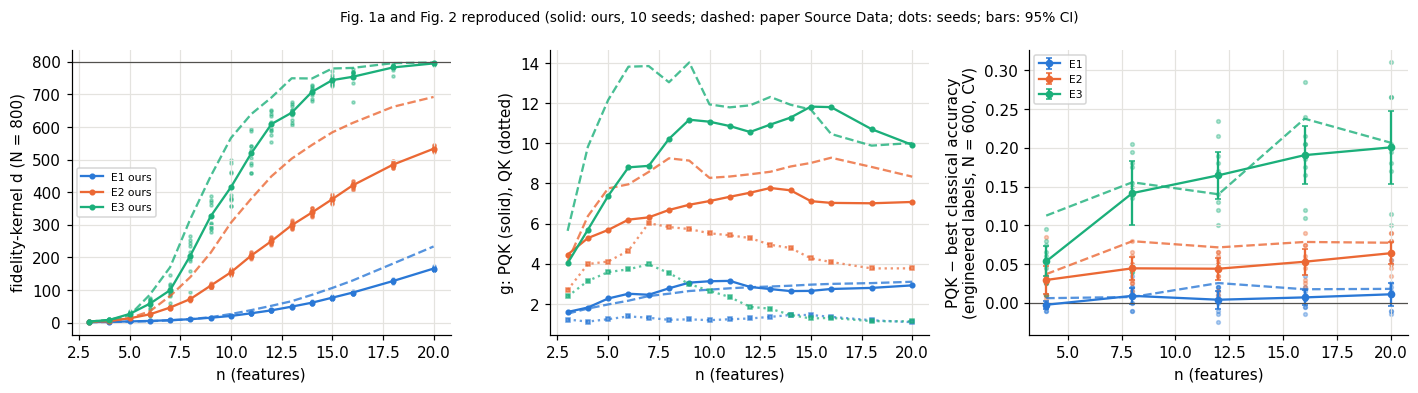

In [9]:
def rows(frame, component, quantity, protocol=None, train_size=None):
    out = frame[(frame.component == component) & (frame.quantity == quantity)]
    out = out[out.protocol.isna()] if protocol is None else out[out.protocol == protocol]
    if train_size is not None:
        out = out[out.train_size == train_size]
    return out.sort_values("n")

def seeds(family, component, quantity, protocol=None, train_size=None):
    out = PER_SEED[(PER_SEED.family == family) & (PER_SEED.component == component) & (PER_SEED.quantity == quantity)]
    out = out[out.protocol.isna()] if protocol is None else out[out.protocol == protocol]
    return out if train_size is None else out[out.train_size == train_size]

def paper_difference(frame, component, quantum, protocol, train_size):
    q = rows(frame, component, quantum, protocol, train_size).set_index(["embedding", "n"]).paper_value
    c = rows(frame, component, "best_classical", protocol, train_size).set_index(["embedding", "n"]).paper_value
    return (q - c).dropna()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for emb in ("E1", "E2", "E3"):
    color = COLORS[emb]
    d = rows(GATE, "dimension_geometry", "d_quantum_kernel"); d = d[d.embedding == emb]
    per = seeds("gate", "dimension_geometry", "d_quantum_kernel"); per = per[per.embedding == emb]
    axes[0].scatter(per.n, per.value, s=4, color=color, alpha=0.4)
    axes[0].plot(d.n, d["mean"], "o-", color=color, ms=3, label=f"{emb} ours")
    axes[0].plot(d.n, d.paper_value, "--", color=color, alpha=0.8)
    g = rows(GATE, "dimension_geometry", "g_projected_quantum_kernel"); g = g[g.embedding == emb]
    axes[1].plot(g.n, g["mean"], "o-", color=color, ms=3, label=f"{emb} PQK")
    axes[1].plot(g.n, g.paper_value, "--", color=color, alpha=0.8)
    gq = rows(GATE, "dimension_geometry", "g_quantum_kernel"); gq = gq[gq.embedding == emb]
    axes[1].plot(gq.n, gq["mean"], "s:", color=color, ms=3, alpha=0.7)
    diff = rows(GATE, "engineered_pqk", "projected_quantum_kernel_minus_best_classical", "cv", 600); diff = diff[diff.embedding == emb]
    per = seeds("gate", "engineered_pqk", "projected_quantum_kernel_minus_best_classical", "cv", 600); per = per[per.embedding == emb]
    axes[2].scatter(per.n, per.value, s=6, color=color, alpha=0.35)
    axes[2].errorbar(diff.n, diff["mean"], yerr=diff.ci95_half_width, fmt="o-", color=color, ms=4, capsize=2, label=emb)
    paper = paper_difference(GATE, "engineered_pqk", "projected_quantum_kernel", "cv", 600).loc[emb]
    axes[2].plot(paper.index, paper.values, "--", color=color, alpha=0.8)
axes[0].axhline(800, color="#52514e", lw=0.8); axes[0].set_ylabel("fidelity-kernel d (N = 800)")
axes[1].set_ylabel("g: PQK (solid), QK (dotted)"); axes[2].axhline(0, color="#52514e", lw=0.8)
axes[2].set_ylabel("PQK − best classical accuracy\n(engineered labels, N = 600, CV)")
for ax in axes:
    ax.set_xlabel("n (features)")
axes[0].legend(fontsize=7); axes[2].legend(fontsize=7)
fig.suptitle("Fig. 1a and Fig. 2 reproduced (solid: ours, 10 seeds; dashed: paper Source Data; dots: seeds; bars: 95% CI)", fontsize=9)
plt.tight_layout(); plt.show()

In [10]:
# Headline numbers, read from the stored aggregate (CV selection; paired 95% CI half-width in brackets).
def cell(frame, component, quantity, emb, n, protocol=None, train_size=None):
    r = rows(frame, component, quantity, protocol, train_size)
    r = r[(r.embedding == emb) & (r.n == n)].iloc[0]
    return r

headline = []
for emb in ("E1", "E2", "E3"):
    for n_value in (16, 20):
        d = cell(GATE, "dimension_geometry", "d_quantum_kernel", emb, n_value)
        qk = cell(GATE, "quantum_dataset", "quantum_kernel_minus_best_classical", emb, n_value, "cv", 600)
        pq = cell(GATE, "engineered_pqk", "projected_quantum_kernel_minus_best_classical", emb, n_value, "cv", 600)
        paper_pq = paper_difference(GATE, "engineered_pqk", "projected_quantum_kernel", "cv", 600).loc[(emb, n_value)]
        headline.append({"embedding": emb, "n": n_value,
                         "d_QK ours": round(d["mean"], 1), "d_QK paper": round(d.paper_value, 1),
                         "C1: QK − best MAE": f"{qk['mean']:+.3f} [±{qk.ci95_half_width:.3f}]",
                         "C5: PQK − best acc.": f"{pq['mean']:+.3f} [±{pq.ci95_half_width:.3f}]",
                         "C5 paper": f"{paper_pq:+.3f}"})
display(pd.DataFrame(headline))

,embedding,n,d_QK ours,d_QK paper,C1: QK − best MAE,C5: PQK − best acc.,C5 paper
0,E1,16,92.2,129.2,+0.052 [±0.005],+0.007 [±0.010],+0.018
1,E1,20,165.9,233.6,+0.055 [±0.004],+0.011 [±0.015],+0.018
2,E2,16,420.6,612.1,+0.046 [±0.021],+0.053 [±0.017],+0.079
3,E2,20,533.1,691.9,+0.058 [±0.033],+0.064 [±0.014],+0.077
4,E3,16,753.6,780.9,+0.035 [±0.013],+0.190 [±0.038],+0.238
5,E3,20,794.7,797.5,+0.031 [±0.011],+0.201 [±0.047],+0.207


**Observation.**
- The fidelity kernel's $d$ grows toward N = 800 and its $g$ falls toward 1 as n grows (E3: 795 of 800 at n = 20, paper 798); the PQK keeps a larger $g$ for every embedding.
- On quantum-generated labels the fidelity kernel loses to the classical suite at n = 16 and 20 for all three embeddings (C1).
- On engineered labels the PQK beats the best classical model by +0.19 to +0.20 accuracy for E3 and +0.05 to +0.06 for E2, and ties for E1 (C5). At n = 20 the E3 gap (+0.201) is close to the paper's (+0.207).

**Inference:** the paper's mechanism and claim directions reproduce: data lets classical models match the fidelity kernel, and the projected kernel's advantage appears where $g$ is large, in the order E3 > E2 > E1.

**Remaining uncertainty:**
- the input scale was fitted to the paper's geometry, so the geometry agreement is partly by construction (Section 9);
- E1/E2 effective dimensions grow more slowly than the paper's (for example 92 vs 129 for E1 at n = 16);
- n stops at 20, against the paper's 30.

**Claim impact:** C1, C3, C4 and C5/C6 **reproduced in direction**, with magnitudes close for E3 and smaller for E2.

### Secondary claims C8 (training size) and C9 (bound) 📦 [Reproduction]

Both use the paper's own selection protocol (`paper`, best test score) because they compare values with the paper; neither is used for a verdict on advantage.

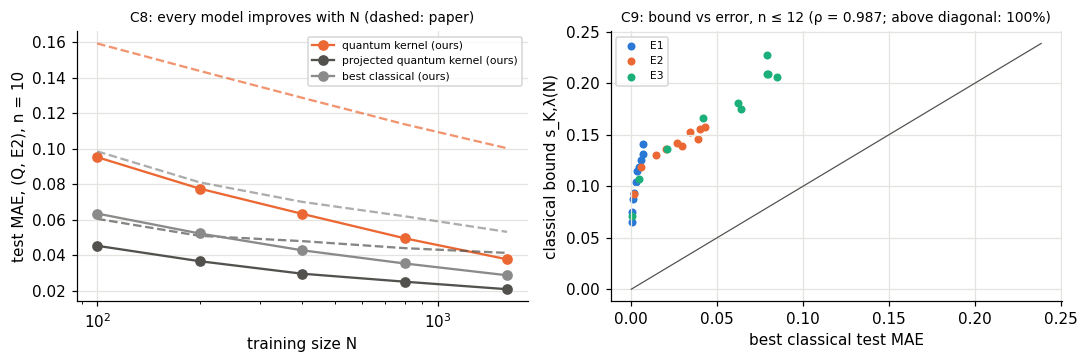

,train_size,PQK − best (ours),PQK − best (paper)
0,100,-0.0182,-0.0380
1,200,-0.0156,-0.0301
2,400,-0.0132,-0.0221
3,800,-0.0103,-0.0180
4,1600,-0.0079,-0.0119


In [11]:
training = pd.DataFrame(json.loads((RESULTS / "training_size_comparison.json").read_text()))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
at10 = training[training.n == 10].sort_values("train_size")
for name, color in (("quantum_kernel", COLORS["E2"]), ("projected_quantum_kernel", "#52514e"), ("best_classical", "#8a8a8a")):
    axes[0].plot(at10.train_size, at10[f"{name}_ours"], "o-", color=color, label=f"{name.replace('_', ' ')} (ours)")
    axes[0].plot(at10.train_size, at10[f"{name}_paper"], "--", color=color, alpha=0.7)
axes[0].set_xscale("log"); axes[0].set_xlabel("training size N"); axes[0].set_ylabel("test MAE, (Q, E2), n = 10")
axes[0].set_title("C8: every model improves with N (dashed: paper)", fontsize=9); axes[0].legend(fontsize=7)

bound = rows(GATE, "bound", "prediction_error_bound", None, 600).set_index(["embedding", "n"])["mean"]
error = rows(GATE, "quantum_dataset", "best_classical", "paper", 600).set_index(["embedding", "n"])["mean"]
pairs = pd.concat([bound.rename("bound"), error.rename("error")], axis=1).dropna()
for emb, sub in pairs.groupby(level="embedding"):
    axes[1].scatter(sub.error, sub.bound, color=COLORS[emb], label=emb, s=18)
lim = [0, pairs.max().max() * 1.05]; axes[1].plot(lim, lim, color="#52514e", lw=0.8)
rho_bound = stats.spearmanr(pairs.bound, pairs.error)[0]
axes[1].set_xlabel("best classical test MAE"); axes[1].set_ylabel("classical bound s_K,λ(N)")
axes[1].set_title(f"C9: bound vs error, n ≤ 12 (ρ = {rho_bound:.3f}; above diagonal: {(pairs.bound >= pairs.error).mean():.0%})", fontsize=9)
axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()
gap = at10.assign(ours=at10.projected_quantum_kernel_ours - at10.best_classical_ours, paper=at10.projected_quantum_kernel_paper - at10.best_classical_paper)
display(gap[["train_size", "ours", "paper"]].rename(columns={"ours": "PQK − best (ours)", "paper": "PQK − best (paper)"}).round(4))

**Observation:**
- **C8.** Every model improves with N, and the PQK − best-classical gap shrinks from −0.018 to −0.008 MAE as N grows from 100 to 1,600 (paper −0.038 → −0.012). Our absolute errors are about 30–40% below the paper's.
- **C9.** The classical bound tracks the actual error (Spearman ρ above) and lies above it at every point.

**Claim impact:** C8 **reproduced in trend** (magnitudes differ); C9 **reproduced**.

## 8. Fair baseline comparison 📦

**Baselines.** The *paper baseline* is the best of six tuned classical families, re-implemented and run inside the same units as the quantum models. As a *strong conventional baseline* we add a polynomial-kernel model (extension) to the same suite. The classical models are not a strawman: they include non-kernel learners (random forest, gradient boosting, AdaBoost, MLP).

**What is matched, and what is not:**

| Dimension | Status | Detail |
|---|---|---|
| Information and inputs | matched | identical standardized PCA features, subsample and labels per seed |
| Training data | matched | the same 600 (or 100) training points per seed for every model |
| Evaluation protocol | matched | same 200 test points, same metric, same selection protocol (verdicts: 5-fold CV) |
| Tuning budget | **not matched, favours classical** | 377 / 215 classical configurations (regression / classification) vs 36 / 18 for QK and 288 / 144 for PQK |
| Parameter count | not matched (not meaningful) | all kernel models have one dual coefficient per training point; tree models and MLPs differ |
| Optimization steps | not matched | convex kernel solvers vs iterative tree / MLP training; each run to its own stopping rule |
| Compute and wall time | not matched | quantum kernels need state simulation; wall-clock per unit is reported in `results/comparison_extended.md` |

Because the tuning budget favours the classical side, any quantum win below is conservative.

In [12]:
# Verdicts under the frozen rule (paired 95% CI over 10 seeds; CV selection), at the largest sizes.
claims = {"C1/C10 quantum dataset (MAE)": 600, "C5/C6 PQK-engineered (accuracy)": 600, "C7 QK-engineered (accuracy)": 600,
          "C10 Dataset (C) natural labels (error)": 600}
selected = COMPARISON[(COMPARISON.family == "gate") & (COMPARISON.protocol == "cv") & COMPARISON.claim.isin(claims)
                      & (COMPARISON.n.isin([8, 12, 16, 20])) & COMPARISON.difference_vs_best.notna() & (COMPARISON.N == 600)]
selected = selected.assign(
    kernel=selected.system.str.extract(r"^(QK|PQK)")[0],
    difference=selected.difference_vs_best.map(lambda d: f"{d['mean']:+.3f} [±{d['ci95']:.3f}]"),
)
display(selected.pivot_table(index=["claim", "kernel", "embedding"], columns="n", values="verdict", aggfunc="first"))

# Strong-baseline check: does adding the polynomial kernel to the classical suite change any engineered-label verdict?
pq = rows(GATE, "engineered_pqk", "projected_quantum_kernel", "cv", 600).set_index(["embedding", "n"])["mean"]
base = rows(GATE, "engineered_pqk", "best_classical", "cv", 600).set_index(["embedding", "n"])["mean"]
ext = rows(GATE, "engineered_pqk", "best_classical_with_extension", "cv", 600).set_index(["embedding", "n"])["mean"]
print(f"largest gain of the extended classical suite over the paper suite (engineered PQK, CV, N=600): {float((ext - base).max()):.4f} accuracy")
print("PQK − extended suite at n = 20:", (pq - ext).xs(20, level="n").round(3).to_dict())

n                                                                      8   \
claim                                  kernel embedding                     
C1/C10 quantum dataset (MAE)           PQK    E1           QUANTUM BETTER   
                                              E2           QUANTUM BETTER   
                                              E3                      TIE   
                                       QK     E1         CLASSICAL BETTER   
                                              E2                      TIE   
                                              E3           QUANTUM BETTER   
C10 Dataset (C) natural labels (error) PQK    E1                      TIE   
                                              E2         CLASSICAL BETTER   
                                              E3         CLASSICAL BETTER   
                                       QK     E1         CLASSICAL BETTER   
                                              E2         CLASSICAL BETTER   
                                              E3         CLASSICAL BETTER   
C5/C6 PQK-engineered (accuracy)        PQK    E1                      TIE   
                                              E2           QUANTUM BETTER   
                                              E3           QUANTUM BETTER   
                                       QK     E1                      TIE   
                                              E2                      TIE   
                                              E3                      TIE   
C7 QK-engineered (accuracy)            PQK    E1                      TIE   
                                              E2                      TIE   
                                              E3           QUANTUM BETTER   
                                       QK     E1                      TIE   
                                              E2           QUANTUM BETTER   
                                              E3           QUANTUM BETTER   

n                                                                      12  \
claim                                  kernel embedding                     
C1/C10 quantum dataset (MAE)           PQK    E1           QUANTUM BETTER   
                                              E2           QUANTUM BETTER   
                                              E3           QUANTUM BETTER   
                                       QK     E1         CLASSICAL BETTER   
                                              E2         CLASSICAL BETTER   
                                              E3         CLASSICAL BETTER   
C10 Dataset (C) natural labels (error) PQK    E1                      TIE   
                                              E2         CLASSICAL BETTER   
                                              E3         CLASSICAL BETTER   
                                       QK     E1         CLASSICAL BETTER   
                                              E2         CLASSICAL BETTER   
                                              E3         CLASSICAL BETTER   
C5/C6 PQK-engineered (accuracy)        PQK    E1                      TIE   
                                              E2           QUANTUM BETTER   
                                              E3           QUANTUM BETTER   
                                       QK     E1         CLASSICAL BETTER   
                                              E2                      TIE   
                                              E3                      TIE   
C7 QK-engineered (accuracy)            PQK    E1                      TIE   
                                              E2                      TIE   
                                              E3           QUANTUM BETTER   
                                       QK     E1                      TIE   
                                              E2           QUANTUM BETTER   
                                              E3           QUANTUM BETTE

largest gain of the extended classical suite over the paper suite (engineered PQK, CV, N=600): 0.0060 accuracy
PQK − extended suite at n = 20: {'E1': 0.011, 'E2': 0.064, 'E3': 0.2}


**Observation:**
- The fidelity kernel (QK) is classical-better on the quantum datasets from n = 12 on for every embedding (at n = 8 it still beats classical for E3), and classical-better or tied on natural labels (C10).
- The PQK is better on the PQK-engineered labels for E2 and E3 and ties for E1.
- Adding the polynomial-kernel family changes the classical score by at most a few thousandths and no verdict.

**Inference:** the PQK's engineered-label advantage survives a fair, larger-budget classical suite plus an extra conventional baseline.

**Remaining uncertainty:**
- the classical suite is stronger than the paper's on some tasks (our best-classical MAE on (Q, E3) is about half the paper's at n = 8), which narrows some gaps;
- parameter count, optimization steps and compute are not matched.

**Claim impact:** C1 and C5/C6 **reproduced** under a fair baseline; C10 reproduced in direction.

## 9. Controls and ablations 📦

A quantum-kernel win on engineered labels could have other explanations. Each control below targets one of them.

| Alternative explanation | Control | Prediction if the paper is right |
|---|---|---|
| A. "The PQK is simply a better kernel for this data" | natural labels (Dataset C) | no PQK advantage on natural labels |
| B. "Engineered labels favour any quantum kernel" | labels engineered for the *fidelity* kernel (C7) | no fidelity-kernel advantage once its $d$ approaches N |
| C. "The advantage is unrelated to $g$" | advantage vs $g$ across embeddings, sizes and both hardware families | advantage grows with $g$ |
| D. "The result depends on test-set selection" | `paper` vs `cv` selection protocols | same direction under CV |
| E. "The fitted input scale creates the effect" | input-scale scan of the parameter-free E1 kernel | the scale matters for $d$, not for the claim direction |

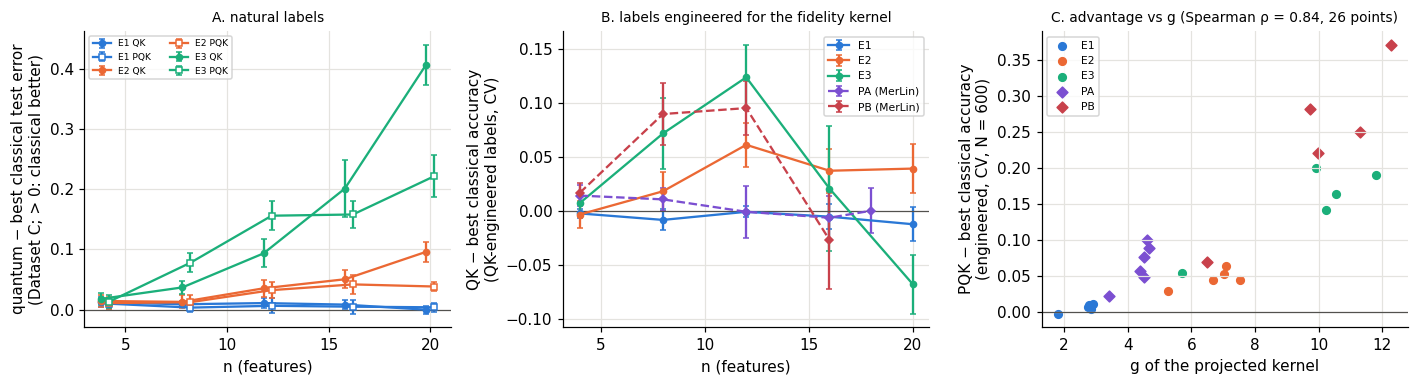

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
# A. Natural labels (Dataset C): every quantum kernel minus the best classical model, test error (> 0: classical better).
for i, emb in enumerate(("E1", "E2", "E3")):
    for kernel_name, marker in (("quantum_kernel", "o"), ("projected_quantum_kernel", "s")):
        per = seeds("gate", "classical_dataset", f"{kernel_name}_{emb}_minus_best_classical", "cv")
        agg = per.groupby("n").value.agg(["mean", "std", "count"])
        axes[0].errorbar(agg.index + (0.2 if marker == "s" else -0.2), agg["mean"],
                         yerr=stats.t.ppf(0.975, agg["count"] - 1) * agg["std"] / np.sqrt(agg["count"]),
                         fmt=marker + "-", color=COLORS[emb], ms=4, capsize=2, mfc="white" if marker == "s" else COLORS[emb],
                         label=f"{emb} {'QK' if marker == 'o' else 'PQK'}")
axes[0].axhline(0, color="#52514e", lw=0.8); axes[0].set_ylabel("quantum − best classical test error\n(Dataset C; > 0: classical better)")
axes[0].set_title("A. natural labels", fontsize=9); axes[0].legend(fontsize=6, ncol=2)

# B. Labels engineered for the fidelity kernel: QK − best classical accuracy.
for emb in ("E1", "E2", "E3"):
    r = rows(GATE, "engineered_qk", "quantum_kernel_minus_best_classical", "cv", 600); r = r[r.embedding == emb]
    axes[1].errorbar(r.n, r["mean"], yerr=r.ci95_half_width, fmt="o-", color=COLORS[emb], ms=4, capsize=2, label=emb)
for emb in ("PA", "PB"):
    r = rows(PHOT, "engineered_qk", "quantum_kernel_minus_best_classical", "cv", 600); r = r[r.embedding == emb]
    axes[1].errorbar(r.n, r["mean"], yerr=r.ci95_half_width, fmt="D--", color=COLORS[emb], ms=4, capsize=2, label=f"{emb} (MerLin)")
axes[1].axhline(0, color="#52514e", lw=0.8); axes[1].set_ylabel("QK − best classical accuracy\n(QK-engineered labels, CV)")
axes[1].set_title("B. labels engineered for the fidelity kernel", fontsize=9); axes[1].legend(fontsize=7)

# C. Advantage vs g, every (embedding, n) with a CV result, gate and photonic.
points = []
for frame, family in ((GATE, "gate"), (PHOT, "photonic"), (CAPPED, "photonic capped")):
    adv = rows(frame, "engineered_pqk", "projected_quantum_kernel_minus_best_classical", "cv", 600).set_index(["embedding", "n"])["mean"]
    g = rows(frame, "dimension_geometry", "g_projected_quantum_kernel").set_index(["embedding", "n"])["mean"]
    joined = pd.concat([g.rename("g"), adv.rename("advantage")], axis=1).dropna()
    for (emb, n_value), r in joined.iterrows():
        points.append((family, emb, n_value, r.g, r.advantage))
points = pd.DataFrame(points, columns=["family", "embedding", "n", "g", "advantage"])
for emb, sub in points.groupby("embedding"):
    axes[2].scatter(sub.g, sub.advantage, color=COLORS[emb], label=emb, s=25, marker="D" if emb.startswith("P") else "o")
rho, p_value = stats.spearmanr(points.g, points.advantage)
axes[2].set_xlabel("g of the projected kernel"); axes[2].set_ylabel("PQK − best classical accuracy\n(engineered, CV, N = 600)")
axes[2].axhline(0, color="#52514e", lw=0.8); axes[2].set_title(f"C. advantage vs g (Spearman ρ = {rho:.2f}, {len(points)} points)", fontsize=9)
axes[2].legend(fontsize=7)
for ax in axes[:2]:
    ax.set_xlabel("n (features)")
plt.tight_layout(); plt.show()

**Observation:**
- **A.** On natural labels no quantum kernel beats the classical suite. Every difference is ≥ 0 within its CI, and the E2/E3 kernels are clearly worse.
- **B.** On labels engineered for the *fidelity* kernel, its advantage disappears as its $d$ approaches N: E3 ties at n = 16 and loses at n = 20, and the photonic PB ties at n = 16. It persists for gate E2 up to n = 20.
- **C.** Across all embeddings, sizes and both hardware families, the PQK's advantage rises with $g$ (Spearman ρ printed above).

**Inference:** the advantage is specific to labels that encode the quantum geometry, and its size is predicted by the label-free $g$. That is the paper's explanation; alternatives A and C are ruled out.

**Remaining uncertainty:** for B, the gate E2 fidelity-kernel advantage persists to n = 20, so "no advantage at large n" is only partially reproduced (the paper's large n is about 28).

**Claim impact:**
- C10 **reproduced** (direction);
- C7 **partially reproduced**;
- the $g$-explanation of C5/C6 **survives the controls**.

paper (test-set selection)  cv (5-fold)  paper − cv
embedding n                                                      
E1        4                        0.000       -0.003       0.003
E2        4                        0.025        0.030      -0.005
E3        4                        0.046        0.054      -0.008
          8                        0.149        0.142       0.007
E1        8                        0.001        0.009      -0.008
E2        8                        0.046        0.045       0.002
E3        12                       0.150        0.164      -0.015
E2        12                       0.046        0.044       0.002
E1        12                       0.005        0.004       0.001
E3        16                       0.185        0.190      -0.005
E2        16                       0.050        0.053      -0.003
E1        16                       0.003        0.007      -0.005
E2        20                       0.061        0.064      -0.003
E1        20                       0.009        0.011      -0.002
E3        20                       0.187        0.201      -0.014

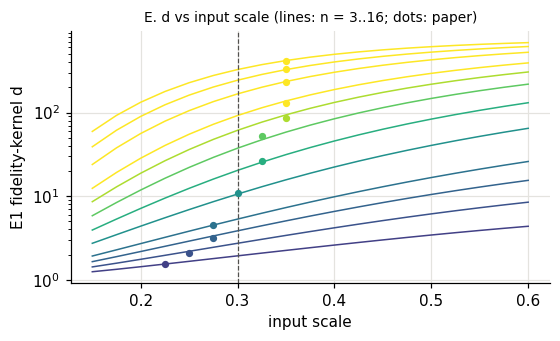

scale that matches the paper's d(E1): {3: 0.225, 4: 0.25, 5: 0.275, 6: 0.275, 8: 0.3, 10: 0.325, 12: 0.325, 14: 0.35, 16: 0.35, 20: 0.35, 24: 0.35, 28: 0.35}


In [14]:
# D. Selection protocol: optimistic test-set selection ('paper') vs 5-fold CV ('cv'), engineered PQK advantage.
paper_sel = rows(GATE, "engineered_pqk", "projected_quantum_kernel_minus_best_classical", "paper", 600).set_index(["embedding", "n"])["mean"]
cv_sel = rows(GATE, "engineered_pqk", "projected_quantum_kernel_minus_best_classical", "cv", 600).set_index(["embedding", "n"])["mean"]
protocol_table = pd.concat([paper_sel.rename("paper (test-set selection)"), cv_sel.rename("cv (5-fold)")], axis=1).dropna()
protocol_table["paper − cv"] = protocol_table.iloc[:, 0] - protocol_table.iloc[:, 1]
display(protocol_table.round(3))

# E. Input-scale scan (diagnostic, E1 analytic kernel, seeds 0-1): which scale matches the paper's d at each n?
scan = json.loads((RESULTS / "diagnostic_input_scale.json").read_text())
fig, ax = plt.subplots(figsize=(5.2, 3.2))
for row in scan["rows"]:
    by_scale = {float(k): v for k, v in row["d_by_scale"].items()}
    ax.plot(list(by_scale), list(by_scale.values()), color=plt.cm.viridis(row["n"] / 16), lw=1)
    ax.scatter([row["best_scale"]], [row["paper_d"]], color=plt.cm.viridis(row["n"] / 16), s=14, zorder=3)
ax.axvline(0.3, color="#52514e", ls="--", lw=0.8); ax.set_yscale("log")
ax.set_xlabel("input scale"); ax.set_ylabel("E1 fidelity-kernel d"); ax.set_title("E. d vs input scale (lines: n = 3..16; dots: paper)", fontsize=9)
plt.tight_layout(); plt.show()
print("scale that matches the paper's d(E1):", {r["n"]: r["best_scale"] for r in scan["rows"]})

**Observation:**
- **D.** Test-set selection and 5-fold CV give PQK advantages within ±0.015 of each other, in both directions, and no sign changes. Test-set selection does not create the effect.
- **E.** The parameter-free E1 kernel's $d$ depends strongly on the input scale. The scale that reproduces the paper's $d$ drifts from 0.225 (n = 3) to 0.35 (n ≥ 14), so our fixed 0.3 matches it only around n = 8.

**Inference:** the verdicts do not depend on test-set selection. The input scale explains why our E1/E2 $d$ grows more slowly than the paper's (a single fixed scale cannot follow the drift).

**Remaining uncertainty:**
- the effective input scale the authors used is unknown, and fitting it to the paper's geometry makes that agreement partly circular;
- a sensitivity check at n = 12 (3 seeds, `LOG.md`, Gap diagnosis) found no claim direction reversed for scales 0.3–0.5 or a periodic QNN boundary, but other n were not checked.

**Claim impact:** the claim directions are robust to the protocol. Absolute geometry values remain **unresolved**.

## 10. Robustness and uncertainty 📦 [Robustness]

Every stored number is a mean over 10 seeds. Here we check three things: that the seeds agree, that the published tables match the raw seeds, and that mixing machines and precisions does not move the results.

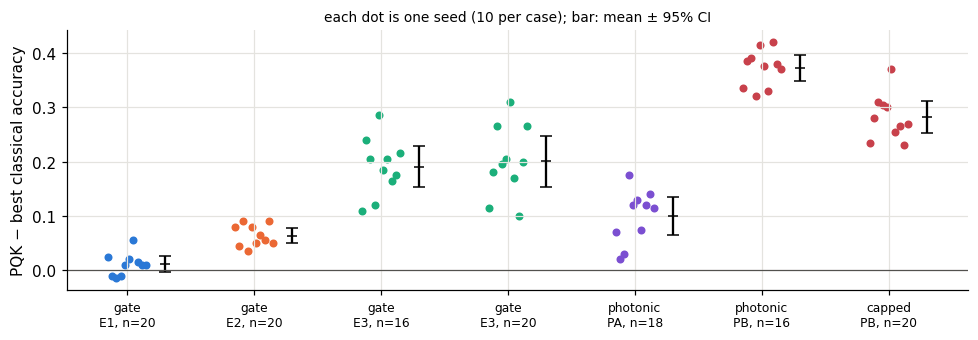

,family,quantity,protocol,cells,max |seed mean − stored mean|,min seeds
0,gate,d_quantum_kernel,None,48,1.136868e-13,10
1,gate,projected_quantum_kernel_minus_best_classical,cv,15,8.326673e-17,10
2,gate,quantum_kernel_minus_best_classical,cv,15,6.982262e-17,10
3,photonic,d_quantum_kernel,None,28,1.136868e-13,10
4,photonic,projected_quantum_kernel_minus_best_classical,cv,9,5.551115e-17,10
5,photonic,quantum_kernel_minus_best_classical,cv,9,5.843850e-17,10
6,photonic_capped,d_quantum_kernel,None,8,1.136868e-13,10
7,photonic_capped,projected_quantum_kernel_minus_best_classical,cv,2,5.551115e-17,10
8,photonic_capped,quantum_kernel_minus_best_classical,cv,2,4.900594e-17,10


In [15]:
# Seed-level view of the decisive engineered-label results (CV, N = 600).
fig, ax = plt.subplots(figsize=(9, 3.2))
cases = [("gate", "E1", 20), ("gate", "E2", 20), ("gate", "E3", 16), ("gate", "E3", 20), ("photonic", "PA", 18), ("photonic", "PB", 16), ("photonic_capped", "PB", 20)]
for i, (family, emb, n_value) in enumerate(cases):
    per = seeds(family, "engineered_pqk", "projected_quantum_kernel_minus_best_classical", "cv", 600)
    values = per[(per.embedding == emb) & (per.n == n_value)].sort_values("seed").value.to_numpy()
    ax.scatter(np.full(values.size, i) + np.linspace(-0.15, 0.15, values.size), values, color=COLORS[emb], s=18)
    half = stats.t.ppf(0.975, values.size - 1) * values.std(ddof=1) / np.sqrt(values.size)
    ax.errorbar(i + 0.3, values.mean(), yerr=half, fmt="k_", capsize=4)
ax.set_xticks(range(len(cases)), [f"{f.replace('photonic_capped', 'capped')}\n{e}, n={n}" for f, e, n in cases], fontsize=8)
ax.axhline(0, color="#52514e", lw=0.8); ax.set_ylabel("PQK − best classical accuracy")
ax.set_title("each dot is one seed (10 per case); bar: mean ± 95% CI", fontsize=9)
plt.tight_layout(); plt.show()

# Stored aggregates must equal the mean of the stored per-seed rows (tables, plots and metrics agree).
check = []
for family, frame in (("gate", GATE), ("photonic", PHOT), ("photonic_capped", CAPPED)):
    for (component, quantity, protocol) in [("dimension_geometry", "d_quantum_kernel", None),
                                            ("engineered_pqk", "projected_quantum_kernel_minus_best_classical", "cv"),
                                            ("quantum_dataset", "quantum_kernel_minus_best_classical", "cv")]:
        per = seeds(family, component, quantity, protocol, 600 if protocol else None)
        recomputed = per.groupby(["embedding", "n"]).value.agg(["mean", "count"])
        stored = rows(frame, component, quantity, protocol, 600 if protocol else None).set_index(["embedding", "n"])[["mean", "count"]]
        joined = recomputed.join(stored, rsuffix="_stored", how="inner")
        check.append((family, quantity, protocol, len(joined), float((joined["mean"] - joined["mean_stored"]).abs().max()),
                      int(joined["count"].min())))
agreement = pd.DataFrame(check, columns=["family", "quantity", "protocol", "cells", "max |seed mean − stored mean|", "min seeds"])
display(agreement)
assert (agreement["max |seed mean − stored mean|"] < 1e-12).all() and (agreement["min seeds"] == 10).all()

**Observation:**
- The decisive E3 and PB advantages are positive for every one of the 10 seeds; E1 straddles zero, as expected from its small $g$.
- Every stored mean equals the mean of its 10 stored seeds, so the tables, plots and metrics agree.

**Cross-machine and precision checks** (recorded in `LOG.md`; the runs are too long to repeat live):
- **Gate:** the same smoke config on the M5 (float64) and the L4 (float32) agrees on the geometry to 1e-11 and on tree-model metrics to 0.007. That residual comes from scikit-learn 1.8 vs 1.9.
- **Photonic:** a seed-0, n = 12 unit rerun on the GPU matches the stored CPU unit. Geometry agrees within 1.3e-4 relative, kernel metrics within 3e-5, and tree models within 0.005 (one test point).
- **Precision:** float32 vs float64 changes $d$ by about 1e-3 relative.

**Remaining uncertainty:**
- CV was run only at n = 4, 8, 12, 16, 20 (gate) and up to 18 (photonic);
- one random interferometer and labelling instance is drawn per (seed, n).

**Claim impact:** the reproduced directions are **robust to seeds, machine and precision**.

## 11. Photonic assessment: the MerLin adaptation [Extension]

The paper has no photonic experiments. We asked whether its methodology carries over to **linear optics** with indistinguishable photons, simulated exactly with MerLin (translation status `MERLIN_IMPLEMENTATION`).

**Mapping.** n features drive m optical modes holding k = ⌊m/2⌋ photons, input $|1,0,1,0,\dots\rangle$:
- **PA** (analogue of the IQP embedding E2): $U(x) = W\,\mathrm{diag}(e^{i\,2\cdot0.3\,x_j})\,V$ with fixed Haar-random interferometers V, W; m = n.
- **PB** (analogue of the Heisenberg chain E3): a 20-step Trotterized bosonic hopping chain, beam splitters between neighbouring modes driven by $x$; m = n + 1.
- **Fidelity kernel**: $|\langle s|U(x')^\dagger U(x)|s\rangle|^2$ from Fock amplitudes; physically, the probability that the detectors see the input pattern again.
- **Projected kernel**: a Gaussian kernel on the per-mode **no-click probabilities** $P(n_k = 0)$, the threshold-detector analogue of one-qubit reduced states (measurable without postselection).
- **Labels**: $P(n_0 = 0)$ after a fixed Haar interferometer.

Everything downstream (subsamples, classical suite, $d$, $g$, engineered labels, protocols, seeds) is shared with the gate study.

In [16]:
# 🟢 live: one small photonic bank with MerLin (PA, n = 6 modes, 3 photons) on the seed-0 subsample.
live_photonic = photonic_merlin.compute_photonic_bank(
    "PA", pca.features(6, indices), input_scale=0.3,
    unitary_rng=study.stream_rng(0, study.STREAM_PHOTONIC_UNITARIES, "PA", 6),
    label_rng=study.stream_rng(0, study.STREAM_QNN, "PA", 6),
    need_quantum_kernel=True, timings=(photonic_timing := {}))
no_click = live_photonic.pauli_features[:, :, 0]
print(f"modes {live_photonic.n_qubits}, photons {photonic_timing['n_photons']}, Fock dimension {photonic_timing['fock_dimension']}, "
      f"800-point bank in {photonic_timing['simulation_seconds'] + photonic_timing['gram_seconds']:.2f} s")
print("no-click probabilities of the first point:", no_click[0].round(3).tolist(),
      f"| sum over modes {no_click[0].sum():.3f} (≥ m − k = 3)")
print(f"fidelity-kernel d = {geometry.effective_dimension(live_photonic.quantum_kernel):.1f} of 800; labels in "
      f"[{live_photonic.qnn_labels.min():.3f}, {live_photonic.qnn_labels.max():.3f}]")

modes 6, photons 3, Fock dimension 56, 800-point bank in 0.12 s
no-click probabilities of the first point: [0.865, 0.715, 0.786, 0.568, 0.501, 0.48] | sum over modes 3.915 (≥ m − k = 3)
fidelity-kernel d = 7.9 of 800; labels in [0.330, 0.733]


**Stored runs** (10 seeds, paper grids). Two regimes, pushed to the memory limit of one NVIDIA L4 GPU:
- **k = ⌊m/2⌋**, n = 4–14 on the laptop CPU and n = 15–18 on the L4. PA reaches n = 18 (18 modes, 9 photons, 3.1 million Fock states); PB reaches n = 17. PB n = 18 would need 19 modes, beyond host memory, and was not run. PB n = 14 has no fidelity kernel (an earlier memory limit).
- **photons capped at k ≤ 8**, n = 17–20: a separate regime whose Fock space grows polynomially. It is identical to the first for m ≤ 17 and never merged with it (hollow markers).

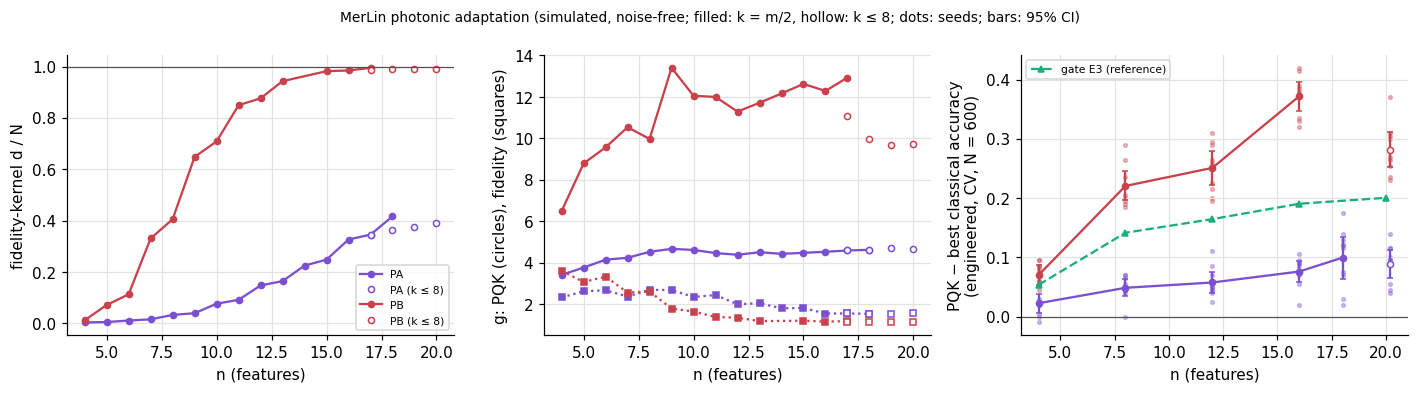

,PA,PB
P1,preserved,preserved
P2,preserved,preserved
P3,preserved,preserved
P4_ci,preserved,preserved


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for emb in ("PA", "PB"):
    for frame, family, hollow in ((PHOT, "photonic", False), (CAPPED, "photonic_capped", True)):
        style = dict(color=COLORS[emb], mfc="white" if hollow else COLORS[emb], ms=4)
        d = rows(frame, "dimension_geometry", "d_quantum_kernel"); d = d[d.embedding == emb]
        axes[0].plot(d.n, d["mean"] / 800, "o" if hollow else "o-", label=f"{emb}{' (k ≤ 8)' if hollow else ''}", **style)
        g = rows(frame, "dimension_geometry", "g_projected_quantum_kernel"); g = g[g.embedding == emb]
        gq = rows(frame, "dimension_geometry", "g_quantum_kernel"); gq = gq[gq.embedding == emb]
        axes[1].plot(g.n, g["mean"], "o" if hollow else "o-", **style)
        axes[1].plot(gq.n, gq["mean"], "s" if hollow else "s:", **style)
        adv = rows(frame, "engineered_pqk", "projected_quantum_kernel_minus_best_classical", "cv", 600); adv = adv[adv.embedding == emb]
        per = seeds(family, "engineered_pqk", "projected_quantum_kernel_minus_best_classical", "cv", 600); per = per[per.embedding == emb]
        axes[2].scatter(per.n + (0.2 if hollow else 0), per.value, color=COLORS[emb], s=6, alpha=0.35)
        axes[2].errorbar(adv.n + (0.2 if hollow else 0), adv["mean"], yerr=adv.ci95_half_width, fmt="o" if hollow else "o-", capsize=2, **style)
e3 = rows(GATE, "engineered_pqk", "projected_quantum_kernel_minus_best_classical", "cv", 600); e3 = e3[e3.embedding == "E3"]
axes[2].plot(e3.n, e3["mean"], "^--", color=COLORS["E3"], ms=4, label="gate E3 (reference)")
axes[0].set_ylabel("fidelity-kernel d / N"); axes[0].axhline(1, color="#52514e", lw=0.8); axes[0].legend(fontsize=7)
axes[1].set_ylabel("g: PQK (circles), fidelity (squares)")
axes[2].set_ylabel("PQK − best classical accuracy\n(engineered, CV, N = 600)"); axes[2].axhline(0, color="#52514e", lw=0.8); axes[2].legend(fontsize=7)
for ax in axes:
    ax.set_xlabel("n (features)")
fig.suptitle("MerLin photonic adaptation (simulated, noise-free; filled: k = m/2, hollow: k ≤ 8; dots: seeds; bars: 95% CI)", fontsize=9)
plt.tight_layout(); plt.show()

preservation = json.loads((RESULTS / "photonic_preservation_extended.json").read_text())
display(pd.DataFrame(preservation["verdicts"]).replace({True: "preserved", False: "NOT preserved"}))

In [18]:
# Photonic verdicts under the same frozen rule (CV, N = 600, paired 95% CI over 10 seeds).
phot = COMPARISON[COMPARISON.family.str.startswith("photonic") & (COMPARISON.protocol == "cv") & (COMPARISON.N == 600)
                  & COMPARISON.difference_vs_best.notna() & COMPARISON.claim.isin(claims)]
phot = phot.assign(kernel=phot.system.str.extract(r"^(QK|PQK)")[0],
                   result=phot.apply(lambda r: f"{r.difference_vs_best['mean']:+.3f} {r.verdict.lower()}", axis=1))
display(phot.pivot_table(index=["claim", "kernel", "embedding"], columns=["family", "n"], values="result", aggfunc="first").fillna(""))

family                                                                  photonic  \
n                                                                             8    
claim                                  kernel embedding                            
C1/C10 quantum dataset (MAE)           PQK    PA         +0.013 classical better   
                                              PB                      +0.005 tie   
                                       QK     PA         +0.008 classical better   
                                              PB         +0.012 classical better   
C10 Dataset (C) natural labels (error) PQK    PA         +0.021 classical better   
                                              PB         +0.184 classical better   
                                       QK     PA         +0.009 classical better   
                                              PB         +0.063 classical better   
C5/C6 PQK-engineered (accuracy)        PQK    PA           +0.049 quantum better   
                                              PB           +0.221 quantum better   
                                       QK     PA                      -0.006 tie   
                                              PB           +0.057 quantum better   
C7 QK-engineered (accuracy)            PQK    PA         -0.045 classical better   
                                              PB           +0.070 quantum better   
                                       QK     PA           +0.011 quantum better   
                                              PB           +0.090 quantum better   

family                                                                            \
n                                                                             12   
claim                                  kernel embedding                            
C1/C10 quantum dataset (MAE)           PQK    PA         +0.011 classical better   
                                              PB                      -0.003 tie   
                                       QK     PA         +0.039 classical better   
                                              PB         +0.006 classical better   
C10 Dataset (C) natural labels (error) PQK    PA         +0.043 classical better   
                                              PB         +0.272 classical better   
                                       QK     PA                      +0.006 tie   
                                              PB         +0.181 classical better   
C5/C6 PQK-engineered (accuracy)        PQK    PA           +0.058 quantum better   
                                              PB           +0.251 quantum better   
                                       QK     PA                      -0.013 tie   
                                              PB                      -0.028 tie   
C7 QK-engineered (accuracy)            PQK    PA         -0.055 classical better   
                                              PB           +0.046 quantum better   
                                       QK     PA                      -0.001 tie   
                                              PB           +0.096 quantum better   

family                                                                            \
n                                                                             16   
claim                                  kernel embedding                            
C1/C10 quantum dataset (MAE)           PQK    PA         +0.009 classical better   
                                              PB                      -0.002 tie   
                                       QK     PA         +0.031 classical better   
                                              PB         +0.002 classical better   
C10 Dataset (C) natural labels (error) PQK    PA         +0.044 classical better   
                                              PB         +0.301 classical better   
                                       QK     PA  

**Observation:**
- The photonic fidelity kernel concentrates: PB reaches d = 0.995 N at 18 modes, and PA rises more slowly (0.42 N at n = 18).
- The projected kernel keeps $g \approx 10$–13 (PB) and ≈ 4.6 (PA), well above the fidelity kernel's.
- On engineered labels the PQK advantage grows with size: PB +0.22 → +0.37 (n = 8 → 16), PA +0.05 → +0.10 (n = 8 → 18), +0.28 and +0.09 in the capped regime at n = 20. At n = 16, PB's PQK stays at 0.92 accuracy while the best classical model falls to 0.55.
- As for the gate model, classical beats the fidelity kernel on the photonic quantum-generated labels, the photonic PQK does not win there, and classical is better or tied on natural labels.
- All predeclared preservation criteria hold.

**Inference:** the paper's methodology is **architecture-agnostic**. $g$ computed from data predicts where a photonic kernel can help, and threshold-detector no-click marginals play the role of one-qubit reduced states.

**Remaining uncertainty:**
- noise-free, lossless simulation only;
- the engineered labels are best-case by construction;
- the photonic label observable differs from the paper's;
- one interferometer instance per (seed, n);
- no paper values exist for this setting.

**Extension verdict:** the mechanism is **preserved and strengthens with size** in simulation. There is no evidence of a photonic advantage on natural data.

In [19]:
# Backend scaling (stored probe on the L4, float32): cost of one 800-point bank vs Fock dimension.
probe = pd.DataFrame(json.loads((RESULTS / "photonic_scaling.json").read_text())["probe"])
probe = probe[probe.status == "measured"].assign(seconds=lambda f: f.simulation_seconds + f.gram_seconds).sort_values("fock_dimension")
display(probe[["embedding", "n", "n_modes", "n_photons", "fock_dimension", "seconds", "peak_device_mb", "peak_host_mb"]]
        .rename(columns={"peak_device_mb": "GPU peak (MB)", "peak_host_mb": "host peak (MB)"}).round(1).reset_index(drop=True))
slope = np.polyfit(np.log(probe.fock_dimension[probe.fock_dimension > 1e5]), np.log(probe.seconds[probe.fock_dimension > 1e5]), 1)[0]
print(f"time ∝ (Fock dimension)^{slope:.2f} above 10^5 states; "
      f"{1e6 * (probe.seconds / probe.fock_dimension)[probe.fock_dimension > 1e5].median():.0f} µs per Fock state per 800-point bank")

,embedding,n,n_modes,n_photons,fock_dimension,seconds,GPU peak (MB),host peak (MB)
0,PA,10,10,5,2002,0.4,64.2,2838.7
1,PB,10,11,5,3003,1.0,100.5,2838.7
2,PA,20,20,5,42504,2.9,1312.1,2838.7
3,PB,20,21,5,53130,5.4,1649.5,2838.7
4,PA,14,14,7,77520,4.8,2754.6,2838.7
5,PB,13,14,7,77520,6.2,2755.3,2838.7
6,PA,15,15,7,116280,7.5,4197.5,2838.7
7,PB,14,15,7,116280,8.7,4198.3,2838.7
8,PA,20,20,6,177100,12.3,4377.6,3010.3
9,PB,20,21,6,230230,19.1,4424.2,3499.9


time ∝ (Fock dimension)^1.05 above 10^5 states; 77 µs per Fock state per 800-point bank


**Backend observations** (`results/photonic_scaling.md`):
- **Time:** grows almost linearly with the Fock dimension.
- **GPU memory:** MerLin's device memory is about 22× the output amplitudes of a batch.
- **Speed:** the L4 was only 1.6–1.8× faster than the laptop CPU where both ran.
- **Ceiling:** host RAM for the 800 stored states the fidelity kernel needs (about 44 GB for the next size, 19 modes with 9 photons).

These points were prepared for the MerLin team in `ACTION_REQUIRED_SEND_TO_MERLIN_TEAM.md`.

## 12. Conclusions

**Separating what was shown:**

| Statement | Status | Evidence |
|---|---|---|
| The software executes and its components give known answers | yes | Section 4; `tests/` (66 pass) |
| The method solves the tasks (models learn the labels) | yes | Sections 6–7 |
| The paper's metrics reproduce | **partly**: directions everywhere; E3 magnitudes close (PQK gap +0.201 vs +0.207 at n = 20); E1/E2 $d$, the E2 gap, and Dataset (C) errors differ | Section 7, `README.md` results table |
| The paper's explanation survives controls | yes: natural labels, labels engineered for the other kernel, advantage vs $g$, selection protocol | Section 9 |
| A quantum kernel beats a fair baseline | the **projected** kernel on engineered labels (E2, E3) and on QNN-generated labels; the fidelity kernel only at small n; **neither on natural labels** | Sections 8–9 |

**1. What reproduced:**
- C1, classical ≥ fidelity kernel on quantum labels (§7, §8);
- C3/C4, fidelity-kernel concentration and the PQK's larger $g$ (§7);
- C5/C6, the engineered-label PQK advantage following $g$ against the full classical suite plus an extra baseline (§7, §8, §9C);
- C10, classical best on natural labels (§9A);
- C8 (the gap shrinks with training size, in trend) and C9 (the bound tracks the error) (§7, secondary claims).

**2. What did not reproduce:**
- the absolute effective dimensions of E1/E2 (§7, §9E);
- the size of the E2 engineered gap (+0.05 vs +0.08 at n = 16);
- the Dataset (C) errors of the E2/E3 kernels, which are much lower than the paper's (`README.md`, Gaps).

**3. What remains unresolved:**
- the effective input scale the authors used (§9E);
- why our classical suite is stronger on some tasks (§8);
- whether the gate E2 fidelity-kernel advantage on its own engineered labels vanishes at the paper's large n (§9B).

**4. What was not attempted:**
- n = 21–30 (the paper's petaflop-scale range);
- the complexity-theoretic results (discrete-log learning, BPP vs BQP);
- hardware or QPU execution;
- noise models for the photonic study.

**5. Reproduction verdict: qualitative reproduction.**
- **Reproduced in direction:** all tested claims at n ≤ 20.
- **Partially reproduced:** C7.
- **Magnitudes:** close for E3, different for E1/E2.
- **Confidence:** MEDIUM for the reproduction, because conventions were inferred and fitted to the paper's geometry; HIGH for the implementation.
- **No quantum advantage on natural data**, consistent with the paper's own message.

**6. Extension / photonic verdict:** the methodology carries over to linear optics in MerLin simulation (§11).
- All preservation criteria hold.
- The hopping-chain embedding behaves like E3, and its engineered-label advantage grows to +0.37 by 18 modes.
- This is simulated, noise-free and best-case-label evidence only.

## Limitations

- **Reduced scale:** n ≤ 20 against the paper's 30; CV only at selected sizes; one interferometer instance per (seed, n).
- **Simulator differences:** a PyTorch statevector simulator replaces TensorFlow-Quantum; inferred circuit conventions (E2 phase, E3 register and time, QNN boundary, PQK bandwidth, median label threshold).
- **Fitted input scale:** 0.3, fitted to the paper's geometry.
- **Mixed hardware:** n ≥ 18 (gate) and photonic n ≥ 15 ran in float32 on a GPU with a newer scikit-learn (bridged, §10).
- **Regenerated labels:** the paper released no features or labels.
- **Photonic study:** noise-free, lossless simulation; the n = 20 photonic results use a capped photon number (a different regime); PB n = 14 lacks a fidelity kernel, and PB n = 18 was not run.
- **Live parts of this notebook:** smoke grids, 3 seeds, n ≤ 8. They illustrate; the stored runs decide.

In [20]:
print(f"notebook finished in {time.perf_counter() - NOTEBOOK_STARTED:.0f} s on {DEVICE}")

notebook finished in 237 s on cpu
